# DE vs ALC: base rank (r=8) vs high rank (r=40, sweep dhp5wasn)

Restricted version of the "DE vs Curve" section in `analyse_qwen_only_new DS.ipynb` (cells 24-29): only DE and ALC (fixed/pretrained-control-point curve) are compared, no Linear/FLC free-curve baseline. Overlays the LoRA rank-40 rerun of the ALC sweep (`dhp5wasn`, still running) on top of the original rank-8 results, reusing the palette slots the original plot used for FLC since FLC isn't shown here.

### init

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
from copy import deepcopy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

n_name = r"$N$"
free_model_name = "FLC"
pretrained_model_name = "ALC"

%load_ext autoreload
%autoreload 2

In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX
                            using \\showthe\\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    "text.usetex": True,
    "font.family": "Nimbus Sans",
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


### Load sweep results (shared helper)

Same per-run field extraction as the `Collect all bezier segments data` section of `analyse_qwen_only_new DS.ipynb`: for every finished run we log its PPD row, and if it's a `Pretraining=True` (fixed control point) run we additionally log the DE row and the PPD-Uniform (BMA over the curve) row.

In [3]:
api = wandb.Api()


def collect_sweep_results(sweep_ids, project="qwen_PtoC_newDS", entity="ddold"):
    results = []
    for s in set(sweep_ids):
        t_run = tqdm(api.sweep(f"{entity}/{project}/{s}").runs)
        t_run.set_description(s)
        for run in t_run:
            if run.state != "finished":
                continue
            t_run.set_postfix_str(run.name)
            mp = run.config["model_params"]
            lora = mp["lora_params"]

            NCurveSegment = mp["num_curve_segment"]
            CurveDegree = mp["SegDeg"]
            res = dict(
                Id=run.id,
                CurveSpace=NCurveSegment * CurveDegree,
                NumPretrained=NCurveSegment + 1 if mp["Pretraining"] else 0,
                Jitter=mp["jitter_multiplier"],
                Seed=run.config["rng_seed"],
                WeightDecay=run.config["optimizer_conf"]["kwargs"]["weight_decay"],
                Dataset="_".join(run.config["data"]["dataset_path"].split("/")[-1].split(".")[0].split("_")[:-1]),
                BmaMode="PPD",
                LoraMode=lora.get("lora_mode", "None"),
                CurveMode=mp.get("curve_parameterization", "Bezier"),
                LoraRank=lora.get("r", -1),
                LoraRho=lora.get("lora_rho", -1),
                CurveSegmentDegree=CurveDegree,
                NCurveSegment=NCurveSegment,
                N=NCurveSegment + 1,
                M=CurveDegree - 1,
                N_cps=NCurveSegment * CurveDegree + 1,
                acc=run.summary.get("test_ppd_acc", -np.inf),
                ece=run.summary.get("test_ppd_ece", -np.inf),
                ll=run.summary.get("test_ppd_ll", -np.inf),
                brier=run.summary.get("test_ppd_brier", -np.inf),
                test_mean_entropy_ppd=run.summary.get("test_ppd_weighted_mean_entropy", -np.inf),
                test_mutual_information_ppd=run.summary.get("test_ppd_weighted_mutual_information", -np.inf),
                test_std_entropy_along_curve=0,
                test_mean_entropy_along_curve=0,
                SweepId=s,
            )
            results.append(res)

            if mp["Pretraining"]:
                _res = deepcopy(res)
                _res["BmaMode"] = "DE"
                _res["acc"] = run.summary.get("test_DE_acc", -np.inf)
                _res["ece"] = run.summary.get("test_DE_ece", -np.inf)
                _res["ll"] = run.summary.get("test_DE_ll", -np.inf)
                _res["brier"] = run.summary.get("test_DE_brier", -np.inf)
                _res["test_mean_entropy_ppd"] = run.summary.get("test_DE_uniform_mean_entropy", -np.inf)
                _res["test_mutual_information_ppd"] = run.summary.get("test_DE_uniform_mutual_information", -np.inf)
                _res["test_std_entropy_along_curve"] = run.summary.get("test_DE_uniform_std_entropy_along_curve", -np.inf)
                _res["test_mean_entropy_along_curve"] = run.summary.get("test_DE_uniform_mean_entropy_along_curve", -np.inf)
                results.append(_res)

            _res = deepcopy(res)
            _res["BmaMode"] = "PPD Uniform"
            _res["acc"] = run.summary.get("test_ppd_uniform_acc", -np.inf)
            _res["ece"] = run.summary.get("test_ppd_uniform_ece", -np.inf)
            _res["ll"] = run.summary.get("test_ppd_uniform_ll", -np.inf)
            _res["brier"] = run.summary.get("test_ppd_uniform_brier", -np.inf)
            _res["test_mean_entropy_ppd"] = run.summary.get("test_ppd_uniform_mean_entropy", -np.inf)
            _res["test_mutual_information_ppd"] = run.summary.get("test_ppd_uniform_mutual_information", -np.inf)
            _res["test_std_entropy_along_curve"] = run.summary.get("test_ppd_uniform_std_entropy_along_curve", -np.inf)
            _res["test_mean_entropy_along_curve"] = run.summary.get("test_ppd_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)

    return pd.DataFrame(results)


def clean_df(df):
    cols = [col for col in df.columns if col[0].isupper()]
    idx_config_with_nan = df.isnull().values.any(axis=1)
    if idx_config_with_nan.any():
        print(f"Dropping {idx_config_with_nan.sum()} rows with missing config values")
    df_clean = df[~idx_config_with_nan].copy()
    idx_ids = [col for col in df.columns if col[0].isupper()]
    value_ids = np.setdiff1d(df.columns.values, idx_ids)
    return df_clean, idx_ids, value_ids

### Load base-rank (r=8) data — ALC/DE main sweep + boolq

In [4]:
# we8wq8n7: PretrainedFlat_Seg(1,2,4,8) (ALC), rank=8, all datasets except boolq
# kru2lo9d: PretrainedBoolq, rank=8, boolq only
df_base_raw = collect_sweep_results(["we8wq8n7", "kru2lo9d"])
df_clean_base, idx_ids, value_ids = clean_df(df_base_raw)
print(f"Base-rank (r=8): {len(df_clean_base)} rows, LoraRank={sorted(df_clean_base['LoraRank'].unique())}")
df_clean_base.head()

  0%|          | 0/40 [00:00<?, ?it/s]

kru2lo9d:   0%|          | 0/40 [00:00<?, ?it/s]

kru2lo9d:   0%|          | 0/40 [00:00<?, ?it/s, autumn-sweep-40]

kru2lo9d:   0%|          | 0/40 [00:00<?, ?it/s, genial-sweep-39]

kru2lo9d:   0%|          | 0/40 [00:00<?, ?it/s, daily-sweep-38] 

kru2lo9d:   0%|          | 0/40 [00:00<?, ?it/s, dazzling-sweep-37]

... (249 outputs left out)

we8wq8n7:  96%|█████████▌| 191/200 [00:01<00:00, 154.15it/s, splendid-sweep-1]

we8wq8n7: 100%|██████████| 200/200 [00:01<00:00, 166.47it/s, splendid-sweep-1]

Base-rank (r=8): 720 rows, LoraRank=[8]


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,N_cps,acc,ece,ll,brier,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,SweepId
0,o83hf81q,24,9,0,8000,0.001,boolq,PPD,A(t)eB(t),bezier,...,25,0.893884,0.037274,-0.278026,0.163006,0.190606,0.000000,0.000000,0.000000,kru2lo9d
1,o83hf81q,24,9,0,8000,0.001,boolq,DE,A(t)eB(t),bezier,...,25,0.896330,0.014473,-0.252129,0.150012,0.245412,0.018772,0.028218,0.226640,kru2lo9d
2,o83hf81q,24,9,0,8000,0.001,boolq,PPD Uniform,A(t)eB(t),bezier,...,25,0.887462,0.033181,-0.274286,0.160473,0.335286,0.066591,0.078766,0.268696,kru2lo9d
3,2m2hztdy,24,9,0,400,0.001,boolq,PPD,A(t)eB(t),bezier,...,25,0.891437,0.016578,-0.269570,0.160647,0.264777,0.000000,0.000000,0.000000,kru2lo9d
4,2m2hztdy,24,9,0,400,0.001,boolq,DE,A(t)eB(t),bezier,...,25,0.894190,0.018049,-0.258440,0.153823,0.273649,0.016095,0.035981,0.257555,kru2lo9d


### Load high-rank (r=40) data — sweep `dhp5wasn`

This sweep is still running (partial results: as of writing, `winogrande_m` has full N/M coverage, `obqa` has a few N=2,M=1 runs, other datasets not started). Only the PPD-Uniform (curve BMA) rows are kept — we're overlaying the higher-rank *curve* result, not a second DE baseline.

In [5]:
df_highrank_raw = collect_sweep_results(["dhp5wasn"])
df_clean_highrank, _, _ = clean_df(df_highrank_raw)
df_clean_highrank = df_clean_highrank[df_clean_highrank["BmaMode"].isin(["DE", "PPD Uniform"])].copy()
print(f"High-rank (r=40): {len(df_clean_highrank)} rows, LoraRank={sorted(df_clean_highrank['LoraRank'].unique())}")
df_clean_highrank.head()

  0%|          | 0/172 [00:00<?, ?it/s]

dhp5wasn:   0%|          | 0/172 [00:00<?, ?it/s]

dhp5wasn:  12%|█▏        | 21/172 [00:00<00:01, 108.12it/s]

dhp5wasn:  30%|██▉       | 51/172 [00:00<00:00, 185.59it/s]

dhp5wasn:  30%|██▉       | 51/172 [00:00<00:00, 185.59it/s, noble-sweep-125]

dhp5wasn:  30%|██▉       | 51/172 [00:00<00:00, 185.59it/s, effortless-sweep-124]

... (96 outputs left out)

dhp5wasn:  94%|█████████▎| 161/172 [00:01<00:00, 155.98it/s, silvery-sweep-2] 

dhp5wasn: 100%|██████████| 172/172 [00:01<00:00, 169.96it/s, silvery-sweep-2]

High-rank (r=40): 188 rows, LoraRank=[40]


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,N_cps,acc,ece,ll,brier,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,SweepId
1,oo56iksf,2,2,0,8000,0.001,ARC-Challenge,DE,A(t)eB(t),bezier,...,3,0.892977,0.026477,-0.298714,0.158412,0.306068,0.015150,0.021324,0.290917,dhp5wasn
2,oo56iksf,2,2,0,8000,0.001,ARC-Challenge,PPD Uniform,A(t)eB(t),bezier,...,3,0.889632,0.028150,-0.308798,0.159604,0.344460,0.017533,0.053710,0.326927,dhp5wasn
4,cpdbj21h,2,2,0,400,0.001,ARC-Challenge,DE,A(t)eB(t),bezier,...,3,0.886288,0.067694,-0.365628,0.163032,0.140648,0.031033,0.013623,0.109615,dhp5wasn
5,cpdbj21h,2,2,0,400,0.001,ARC-Challenge,PPD Uniform,A(t)eB(t),bezier,...,3,0.913043,0.061626,-0.341017,0.147190,0.131227,0.039130,0.016246,0.092096,dhp5wasn
7,ksobzvck,2,2,0,20,0.001,ARC-Challenge,DE,A(t)eB(t),bezier,...,3,0.899666,0.062566,-0.313608,0.164183,0.176362,0.014336,0.022628,0.162026,dhp5wasn


### Build `Model` labels, filter, and merge into one plotting frame

In [6]:
LORA_RHO = 0.25

# --- base rank (r=8): DE + ALC ---
df_base = df_clean_base[
    (df_clean_base["LoraMode"] == "A(t)eB(t)")
    & (df_clean_base["LoraRho"] == LORA_RHO)
    & (df_clean_base["BmaMode"].isin(["DE", "PPD Uniform"]))
].copy()


def map_model_base(r):
    if r["BmaMode"] == "DE":
        return "DE"
    return f"{pretrained_model_name}(N,{r['M']})"


df_base["Model"] = df_base.apply(map_model_base, axis=1)

# --- high rank (r=40): DE + ALC, rank-subscripted labels ---
df_highrank = df_clean_highrank[
    (df_clean_highrank["LoraMode"] == "A(t)eB(t)")
    & (df_clean_highrank["LoraRho"] == LORA_RHO)
].copy()


def map_model_highrank(r):
    if r["BmaMode"] == "DE":
        return f"DE$_{{{int(r['LoraRank'])}}}$"
    return f"{pretrained_model_name}$_{{{int(r['LoraRank'])}}}$(N,{r['M']})"


df_highrank["Model"] = df_highrank.apply(map_model_highrank, axis=1)

df_plot_base = df_base.melt(id_vars=idx_ids + ["Model"], value_vars=value_ids, var_name="Metric", value_name="value")
df_plot_highrank = df_highrank.melt(id_vars=idx_ids + ["Model"], value_vars=value_ids, var_name="Metric", value_name="value")

df_plot = pd.concat([df_plot_base, df_plot_highrank], ignore_index=True)
df_plot["N"] = df_plot["N"].astype(str)
print(df_plot["Model"].unique())
df_plot.head()

['DE' 'ALC(N,2)' 'ALC(N,1)' 'DE$_{40}$' 'ALC$_{40}$(N,1)'
 'ALC$_{40}$(N,2)']


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,LoraRho,CurveSegmentDegree,NCurveSegment,N,M,N_cps,SweepId,Model,Metric,value
0,o83hf81q,24,9,0,8000,0.001,boolq,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,kru2lo9d,DE,acc,0.896330
1,o83hf81q,24,9,0,8000,0.001,boolq,PPD Uniform,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,kru2lo9d,"ALC(N,2)",acc,0.887462
2,2m2hztdy,24,9,0,400,0.001,boolq,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,kru2lo9d,DE,acc,0.894190
3,2m2hztdy,24,9,0,400,0.001,boolq,PPD Uniform,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,kru2lo9d,"ALC(N,2)",acc,0.896942
4,ksxw8pf4,24,9,0,2,0.001,boolq,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,kru2lo9d,DE,acc,0.897248


### Palette

Reuses the same `tab20c` indices as the original notebook's DE-vs-Curve plot for DE and ALC(N,1)/ALC(N,2), and reuses the indices that plot used for FLC(N,1)/FLC(N,2) for the rank-40 series, so the high-rank overlay renders in "the FLC color".

In [7]:
rank40 = int(df_highrank["LoraRank"].iloc[0]) if len(df_highrank) else 40

hue_order = [
    "DE",
    f"{pretrained_model_name}(N,1)",
    f"{pretrained_model_name}(N,2)",
    f"{pretrained_model_name}$_{{{rank40}}}$(N,1)",
    f"{pretrained_model_name}$_{{{rank40}}}$(N,2)",
]
_pal = sns.color_palette("tab20c")
hue_palette = {
    "DE": _pal[5],
    f"{pretrained_model_name}(N,1)": _pal[2],
    f"{pretrained_model_name}(N,2)": _pal[0],
    f"{pretrained_model_name}$_{{{rank40}}}$(N,1)": _pal[10],
    f"{pretrained_model_name}$_{{{rank40}}}$(N,2)": _pal[8],
}
hue_order = [m for m in hue_order if m in set(df_plot["Model"].unique())]
hue_palette = {k: v for k, v in hue_palette.items() if k in hue_order}
hue_order

['DE', 'ALC(N,1)', 'ALC(N,2)', 'ALC$_{40}$(N,1)', 'ALC$_{40}$(N,2)']

### Sanity check: how complete is the high-rank sweep so far?

In [8]:
df_plot[df_plot["Metric"] == "ll"].groupby(["Dataset", "N", "M", "Model"]).size().rename("n_runs")

Dataset        N  M  Model          
ARC-Challenge  2  1  ALC$_{40}$(N,1)    5
                     ALC(N,1)           5
                     DE                 5
                     DE$_{40}$          5
                  2  ALC(N,2)           5
                                       ..
winogrande_s   5  2  DE$_{40}$          5
               9  1  ALC(N,1)           5
                     DE                 5
                  2  ALC(N,2)           5
                     DE                 5
Name: n_runs, Length: 134, dtype: int64

### Plot: DE vs ALC, log-likelihood, base rank vs high rank

/tmp/ipykernel_1134886/929491133.py:8: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


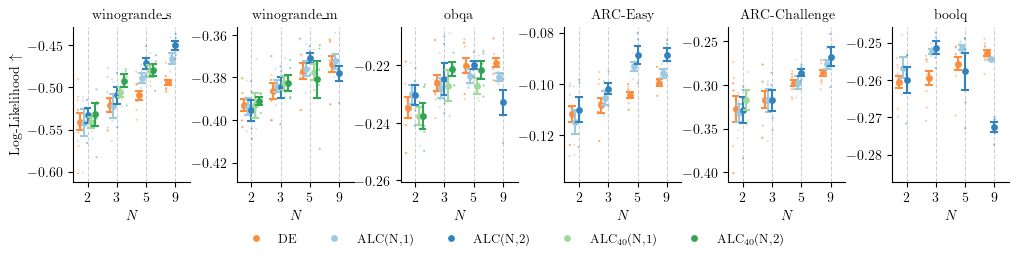

In [9]:
x_name = "N"
df_plot_ll = df_plot[df_plot["Metric"] == "ll"].copy()

full_ds_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
col_order_ds = [d for d in full_ds_order if d in df_plot_ll["Dataset"].unique()]
order = sorted(df_plot_ll[x_name].unique())

g = sns.catplot(
    data=df_plot_ll, y="value", x=x_name,
    col="Dataset", col_wrap=min(6, len(col_order_ds)),
    col_order=col_order_ds,
    order=order,
    kind="point", join=False, capsize=.2, linewidth=1.5,
    markers="o", palette=hue_palette, hue="Model",
    dodge=0.5, sharey=False, sharex=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll["Dataset"] == ds]
    sns.stripplot(
        data=subset, y="value", x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.5, hue="Model", legend=False, hue_order=hue_order,
    )
    ax.grid(True, axis="x", linestyle="--", alpha=0.6)
    ax.set_ylabel("")

    def only_finite(x):
        return x[np.isfinite(x)]

    non_map_vals = only_finite(subset["value"])
    if not non_map_vals.empty:
        ax.set_ylim(bottom=non_map_vals.min() - 0.01)

g.axes[0].set_ylabel(r"Log-Likelihood $\uparrow$")
g.set_titles(col_template="{col_name}")
g.set_xlabels(n_name)
g.tight_layout()
g.fig.subplots_adjust(wspace=0.4)

sns.move_legend(g, loc="lower center", bbox_to_anchor=(0.45, -0.08), ncol=len(hue_order), title="")

os.makedirs("result", exist_ok=True)
plt.savefig("result/performance_DE_vs_ALC_rank_compare.pdf", dpi=300, bbox_inches="tight")
plt.show()

### Mean LL comparison per (Dataset, N): base rank vs high rank

Mean `ll` (averaged over curve-degree `M` and seeds) for each `(Dataset, N)` config, restricted to
`N in {2, 3, 5}` since that's the current coverage of the still-running high-rank sweep. Columns:
`ALC`/`DE` = base rank (r=8), `ALC_40`/`DE_40` = high rank (r=40, sweep `dhp5wasn`).

In [10]:
N_SUBSET = [2, 3, 5]


def _filtered(df, bmamode):
    return df[
        (df["LoraMode"] == "A(t)eB(t)")
        & (df["LoraRho"] == LORA_RHO)
        & (df["BmaMode"] == bmamode)
        & (df["N"].isin(N_SUBSET))
    ]


def _stat_ll(df, bmamode):
    g = _filtered(df, bmamode).groupby(["Dataset", "N"])["ll"]
    stat = pd.concat([g.mean().rename("mean"), g.std().rename("std")], axis=1)

    def fmt(row):
        if pd.isna(row["mean"]):
            return np.nan
        if pd.isna(row["std"]):
            return f"{row['mean']:.3f}"
        return f"{row['mean']:.3f} ± {2 * row['std']:.3f}"

    return stat.apply(fmt, axis=1)


ll_table = pd.DataFrame({
    "ALC": _stat_ll(df_clean_base, "PPD Uniform"),
    "ALC_40": _stat_ll(df_clean_highrank, "PPD Uniform"),
    "DE": _stat_ll(df_clean_base, "DE"),
    "DE_40": _stat_ll(df_clean_highrank, "DE"),
}).reset_index()

ll_table = ll_table.sort_values(["Dataset", "N"]).reset_index(drop=True)
ll_table

,Dataset,N,ALC,ALC_40,DE,DE_40
0,ARC-Challenge,2,-0.330 ± 0.054,-0.317 ± 0.051,-0.327 ± 0.093,-0.324 ± 0.082
1,ARC-Challenge,3,-0.318 ± 0.053,NaN,-0.317 ± 0.063,NaN
2,ARC-Challenge,5,-0.292 ± 0.027,NaN,-0.298 ± 0.023,NaN
3,ARC-Easy,2,-0.112 ± 0.021,NaN,-0.112 ± 0.020,NaN
4,ARC-Easy,3,-0.104 ± 0.011,NaN,-0.108 ± 0.018,NaN
5,ARC-Easy,5,-0.091 ± 0.012,NaN,-0.104 ± 0.008,NaN
6,boolq,2,-0.258 ± 0.014,NaN,-0.261 ± 0.010,NaN
7,boolq,3,-0.252 ± 0.006,NaN,-0.259 ± 0.012,NaN
8,boolq,5,-0.255 ± 0.016,NaN,-0.256 ± 0.011,NaN
9,obqa,2,-0.230 ± 0.014,-0.238 ± 0.016,-0.235 ± 0.023,-0.237 ± 0.016
